# Laboratorio 3 — Modelos de Deep Learning

## CNN 1, CNN 2 y Red Fully Connected

En este notebook se implementan y evalúan tres modelos de redes neuronales para la clasificación de imágenes del alfabeto ASL: dos redes neuronales convolucionales (CNN) y una red neuronal fully-connected.

Los tres modelos utilizan los mismos conjuntos de entrenamiento, validación y prueba generados durante el preprocesamiento, con imágenes RGB de 64×64 píxeles normalizadas al rango [0, 1].

Para cada arquitectura se entrenará una configuración base y al menos una variación de hiperparámetros. La selección de la mejor configuración de cada arquitectura se realizará utilizando el conjunto de validación. Posteriormente, los modelos seleccionados serán evaluados sobre el conjunto de prueba utilizando accuracy, precision, recall macro y matriz de confusión.

## Setup y verificaciones

### Imports

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

I0000 00:00:1786301930.813974   82861 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786301930.814381   82861 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1786301930.851811   82861 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1786301931.885871   82861 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow: 2.21.0


### Definicion de rutas

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

MODELS_DIR.mkdir(parents=True, exist_ok=True)

### Carga de datos

In [3]:
X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

classes = pd.read_csv(PROCESSED_DIR / "classes.csv")["label"].tolist()

print("Datos cargados correctamente.")

Datos cargados correctamente.


### Verificacion de datos

In [4]:
print("Shapes:")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_test:  {y_test.shape}")

print("\nTipos:")
print("X_train:", X_train.dtype)
print("y_train:", y_train.dtype)

print("\nRango de píxeles:")
print("Mínimo:", X_train.min())
print("Máximo:", X_train.max())

print("\nNúmero de clases:", len(classes))
print(classes)

Shapes:
X_train: (14210, 64, 64, 3)
y_train: (14210,)
X_val:   (3045, 64, 64, 3)
y_val:   (3045,)
X_test:  (3045, 64, 64, 3)
y_test:  (3045,)

Tipos:
X_train: float32
y_train: int64

Rango de píxeles:
Mínimo: 0.0
Máximo: 1.0

Número de clases: 29
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


### Validaciones automaticas

In [5]:
assert X_train.ndim == 4
assert X_val.ndim == 4
assert X_test.ndim == 4

assert X_train.shape[1:] == (64, 64, 3)
assert X_val.shape[1:] == (64, 64, 3)
assert X_test.shape[1:] == (64, 64, 3)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert X_train.min() >= 0.0
assert X_train.max() <= 1.0

assert len(classes) == 29

assert y_train.min() >= 0
assert y_train.max() < len(classes)

print("✓ Todas las verificaciones fueron superadas.")

✓ Todas las verificaciones fueron superadas.


### Verificacion de distribucion

In [6]:
def class_distribution(y, class_names):
    counts = np.bincount(y, minlength=len(class_names))

    return pd.DataFrame({
        "Clase": class_names,
        "Cantidad": counts
    })


train_distribution = class_distribution(y_train, classes)
val_distribution = class_distribution(y_val, classes)
test_distribution = class_distribution(y_test, classes)

distribution_df = pd.DataFrame({
    "Clase": classes,
    "Train": train_distribution["Cantidad"],
    "Validation": val_distribution["Cantidad"],
    "Test": test_distribution["Cantidad"]
})

distribution_df

,Clase,Train,Validation,Test
0,A,490,105,105
1,B,490,105,105
2,C,490,105,105
3,D,490,105,105
4,E,490,105,105
5,F,490,105,105
6,G,490,105,105
7,H,490,105,105
8,I,490,105,105
9,J,490,105,105


### Visualizacion de algunas imagenes preprocesadas

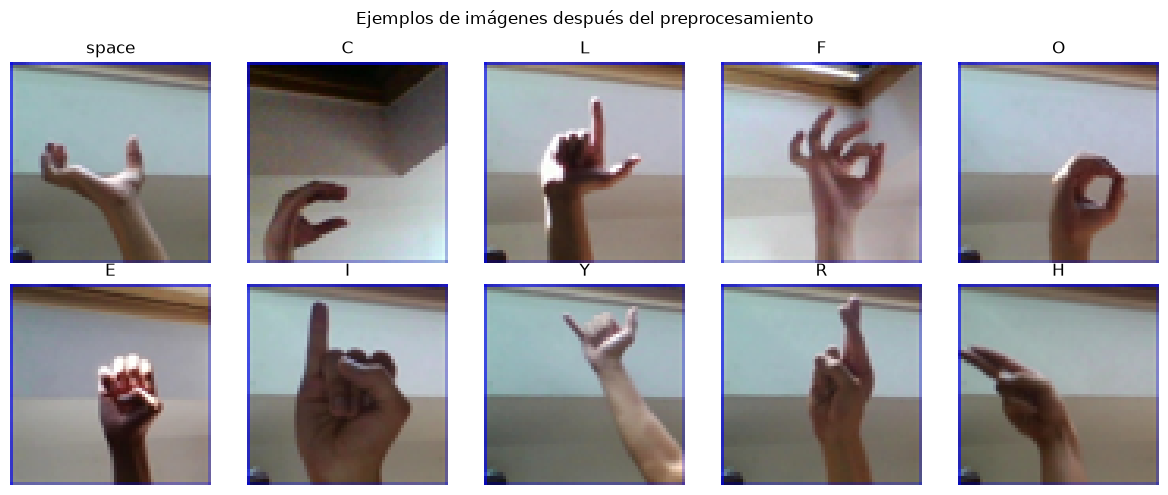

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train[i])
    ax.set_title(classes[y_train[i]])
    ax.axis("off")

plt.suptitle("Ejemplos de imágenes después del preprocesamiento")
plt.tight_layout()
plt.show()

## CNN 1 — Arquitectura sencilla

La primera arquitectura convolucional utiliza dos bloques de convolución y max pooling. El primer bloque utiliza 32 filtros y el segundo 64 filtros, ambos con kernels de 3×3 y activación ReLU.

Después de la extracción de características, los mapas resultantes se aplanan y pasan por una capa densa de 128 neuronas. Se utiliza Dropout de 0.3 para reducir el riesgo de sobreajuste y finalmente una capa de salida de 29 neuronas con activación softmax, una por cada clase.

La configuración base utiliza el optimizador Adam con una tasa de aprendizaje de 0.001 y sparse categorical crossentropy como función de pérdida.

### Funcion de construccion

In [8]:
def build_cnn1(learning_rate=0.001, dropout_rate=0.3):
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            activation="relu"
        ),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu"
        ),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            29,
            activation="softmax"
        )
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [9]:
cnn1_base = build_cnn1(
    learning_rate=0.001,
    dropout_rate=0.3
)

cnn1_base.summary()

E0000 00:00:1786301934.622732   82861 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1786301934.623023   82906 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1786301934.638641   82861 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,628,893 (6.21 MB)

 Trainable params: 1,628,893 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

### Configuracion de entrenamiento

In [10]:
BATCH_SIZE = 32
EPOCHS = 15

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Entrenamiento de CNN1 Base

In [11]:
history_cnn1_base = cnn1_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.3050 - loss: 2.3441 - val_accuracy: 0.6227 - val_loss: 1.2735
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.6288 - loss: 1.1446 - val_accuracy: 0.7829 - val_loss: 0.7086
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.7607 - loss: 0.7144 - val_accuracy: 0.8686 - val_loss: 0.4612
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8253 - loss: 0.5078 - val_accuracy: 0.9123 - val_loss: 0.3223
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.8679 - loss: 0.3850 - val_accuracy: 0.9094 - val_loss: 0.2725
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.8954 - loss: 0.3141 - val_accuracy: 0.9103 - val_loss: 0.2750
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 14s 31ms/step - accuracy: 0.9068 - loss: 0.2754 - val_accuracy: 0.9057 - val_loss: 0.2686
Epoch 8/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.9258 - loss: 0.2207 - 

### Visualizacion de entrenamiento

In [12]:
def plot_training_history(history, title):
    history_df = pd.DataFrame(history.history)

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["accuracy"],
        label="Train"
    )

    plt.plot(
        history_df["val_accuracy"],
        label="Validation"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} — Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

    plt.figure(figsize=(8, 5))

    plt.plot(
        history_df["loss"],
        label="Train"
    )

    plt.plot(
        history_df["val_loss"],
        label="Validation"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} — Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()

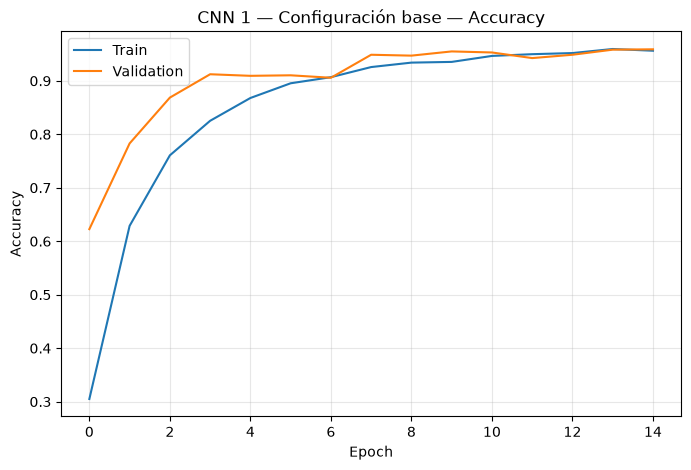

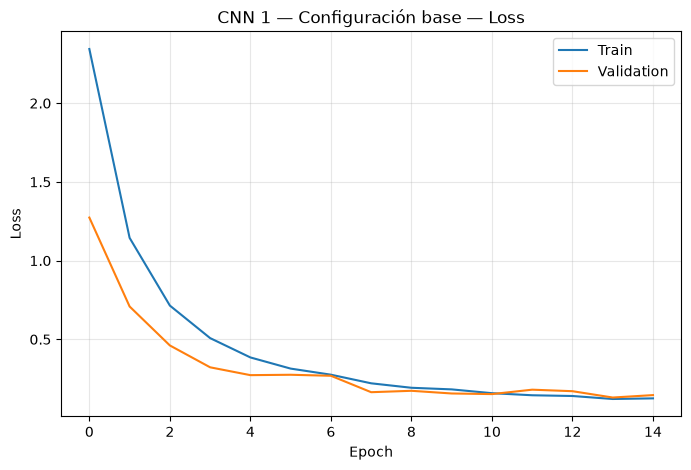

In [13]:
plot_training_history(
    history_cnn1_base,
    "CNN 1 — Configuración base"
)

### Guardar el mejor validation accuracy

In [14]:
cnn1_base_best_val_acc = max(
    history_cnn1_base.history["val_accuracy"]
)

cnn1_base_best_epoch = (
    np.argmax(history_cnn1_base.history["val_accuracy"]) + 1
)

print(
    f"Mejor validation accuracy: "
    f"{cnn1_base_best_val_acc:.4f}"
)

print(
    f"Mejor epoch: "
    f"{cnn1_base_best_epoch}"
)

Mejor validation accuracy: 0.9589
Mejor epoch: 15


## CNN 1 — Variación de hiperparámetros

Para evaluar la sensibilidad de CNN 1 a la tasa de aprendizaje se entrena una segunda configuración manteniendo exactamente la misma arquitectura.

- Configuración base: learning rate = 0.001
- Variante: learning rate = 0.0005

El dropout se mantiene en 0.3 y el resto de la arquitectura permanece sin cambios. De esta manera es posible evaluar específicamente el efecto de reducir la tasa de aprendizaje.

In [15]:
cnn1_variant = build_cnn1(
    learning_rate=0.0005,
    dropout_rate=0.3
)

In [16]:
early_stopping_variant = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [17]:
history_cnn1_variant = cnn1_variant.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_variant],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.2524 - loss: 2.6449 - val_accuracy: 0.5317 - val_loss: 1.6981
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 17s 39ms/step - accuracy: 0.5382 - loss: 1.5162 - val_accuracy: 0.7284 - val_loss: 0.9769
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 37ms/step - accuracy: 0.6825 - loss: 0.9978 - val_accuracy: 0.7964 - val_loss: 0.6881
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 17s 37ms/step - accuracy: 0.7661 - loss: 0.7268 - val_accuracy: 0.8466 - val_loss: 0.5132
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 15s 34ms/step - accuracy: 0.8175 - loss: 0.5682 - val_accuracy: 0.8837 - val_loss: 0.4073
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - accuracy: 0.8517 - loss: 0.4524 - val_accuracy: 0.8834 - val_loss: 0.3752
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 16s 36ms/step - accuracy: 0.8759 - loss: 0.3736 - val_accuracy: 0.8995 - val_loss: 0.3322
Epoch 8/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.8993 - loss: 0.3117 - 

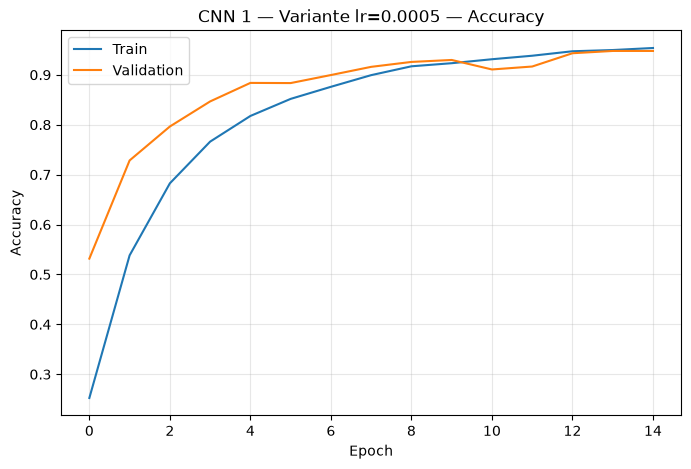

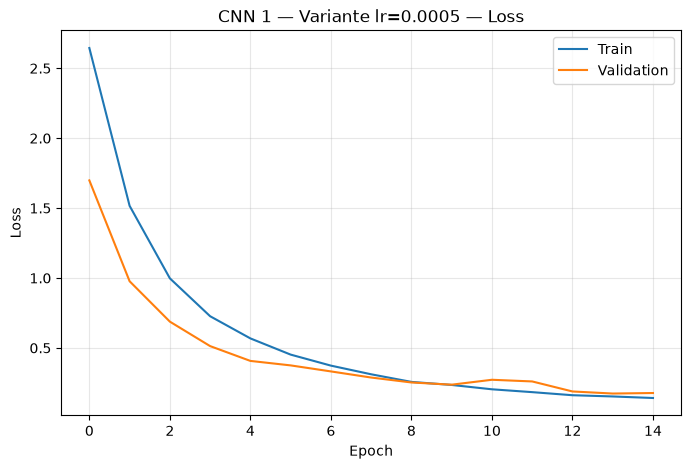

In [18]:
plot_training_history(
    history_cnn1_variant,
    "CNN 1 — Variante lr=0.0005"
)

## Comparacion de CNN1

In [19]:
cnn1_variant_best_val_acc = max(
    history_cnn1_variant.history["val_accuracy"]
)

cnn1_variant_best_epoch = (
    np.argmax(history_cnn1_variant.history["val_accuracy"]) + 1
)

In [20]:
cnn1_results = pd.DataFrame({
    "Configuración": [
        "CNN1 Base",
        "CNN1 lr=0.0005"
    ],
    "Learning rate": [
        0.001,
        0.0005
    ],
    "Dropout": [
        0.3,
        0.3
    ],
    "Mejor val_accuracy": [
        cnn1_base_best_val_acc,
        cnn1_variant_best_val_acc
    ],
    "Mejor epoch": [
        cnn1_base_best_epoch,
        cnn1_variant_best_epoch
    ]
})

cnn1_results

,Configuración,Learning rate,Dropout,Mejor val_accuracy,Mejor epoch
0,CNN1 Base,0.0010,0.3,0.958949,15
1,CNN1 lr=0.0005,0.0005,0.3,0.947783,14


In [21]:
if cnn1_base_best_val_acc >= cnn1_variant_best_val_acc:
    best_cnn1 = cnn1_base
    best_cnn1_name = "CNN1 Base (lr=0.001)"
else:
    best_cnn1 = cnn1_variant
    best_cnn1_name = "CNN1 Variante (lr=0.0005)"

print("Mejor configuración:", best_cnn1_name)

Mejor configuración: CNN1 Base (lr=0.001)


## Resultado de CNN 1

La configuración base de CNN 1 obtuvo el mejor desempeño en validación, alcanzando un accuracy máximo de **0.9589 (95.89%)**, frente a **0.9478 (94.78%)** de la variante con una tasa de aprendizaje de 0.0005.

La reducción del learning rate no produjo una mejora en este caso. Las curvas de entrenamiento y validación presentan un comportamiento similar y la pérdida disminuye progresivamente, sin observarse una separación pronunciada entre ambos conjuntos que indique un sobreajuste significativo.

Por lo tanto, se selecciona **CNN 1 con learning rate = 0.001 y dropout = 0.3** como la mejor configuración de esta arquitectura. La evaluación sobre el conjunto de prueba se realizará posteriormente, una vez seleccionadas las mejores configuraciones de todos los modelos.

## CNN 2 — Arquitectura profunda

La segunda CNN incrementa la profundidad de la red mediante tres bloques convolucionales con 32, 64 y 128 filtros. Cada capa convolucional es seguida por Batch Normalization y Max Pooling.

Batch Normalization permite estabilizar las activaciones durante el entrenamiento, mientras que el incremento progresivo en el número de filtros permite aprender características visuales de mayor complejidad.

Después de la extracción de características se utilizan dos capas densas de 256 y 128 neuronas, acompañadas de Dropout de 0.4 y 0.3 respectivamente. Finalmente, una capa softmax de 29 neuronas genera las probabilidades correspondientes a las clases del dataset.

La configuración base utiliza Adam con learning rate de 0.0005.

### Construccion de CNN2

In [22]:
def build_cnn2(learning_rate=0.0005):
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        # Bloque convolucional 1
        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Bloque convolucional 2
        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Bloque convolucional 3
        layers.Conv2D(
            128,
            kernel_size=(3, 3),
            activation="relu"
        ),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # Clasificación
        layers.Flatten(),

        layers.Dense(
            256,
            activation="relu"
        ),
        layers.Dropout(0.4),

        layers.Dense(
            128,
            activation="relu"
        ),
        layers.Dropout(0.3),

        layers.Dense(
            29,
            activation="softmax"
        )
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [23]:
cnn2_base = build_cnn2(
    learning_rate=0.0005
)

cnn2_base.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 29, 29, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,310,685 (5.00 MB)

 Trainable params: 1,310,237 (5.00 MB)

 Non-trainable params: 448 (1.75 KB)

### Entrenamiento de CNN2 base

In [24]:
early_stopping_cnn2_base = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [25]:
history_cnn2_base = cnn2_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_cnn2_base],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 41s 88ms/step - accuracy: 0.1858 - loss: 2.9021 - val_accuracy: 0.1215 - val_loss: 4.2181
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 38s 86ms/step - accuracy: 0.4202 - loss: 1.9088 - val_accuracy: 0.4654 - val_loss: 2.0163
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 37s 83ms/step - accuracy: 0.5849 - loss: 1.2850 - val_accuracy: 0.7117 - val_loss: 0.8595
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 36s 82ms/step - accuracy: 0.7034 - loss: 0.8826 - val_accuracy: 0.7268 - val_loss: 0.8038
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 37s 82ms/step - accuracy: 0.7849 - loss: 0.6313 - val_accuracy: 0.6430 - val_loss: 1.4624
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 39s 89ms/step - accuracy: 0.8358 - loss: 0.4938 - val_accuracy: 0.8834 - val_loss: 0.3404
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 39s 87ms/step - accuracy: 0.8754 - loss: 0.3600 - val_accuracy: 0.9044 - val_loss: 0.2973
Epoch 8/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 39s 87ms/step - accuracy: 0.9013 - loss: 0.2879 - 

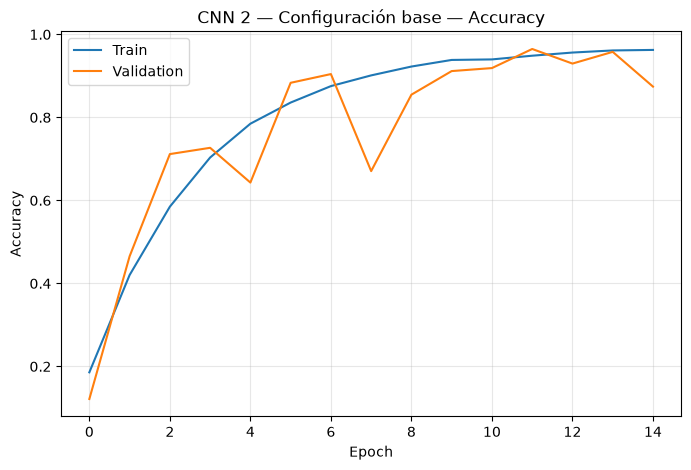

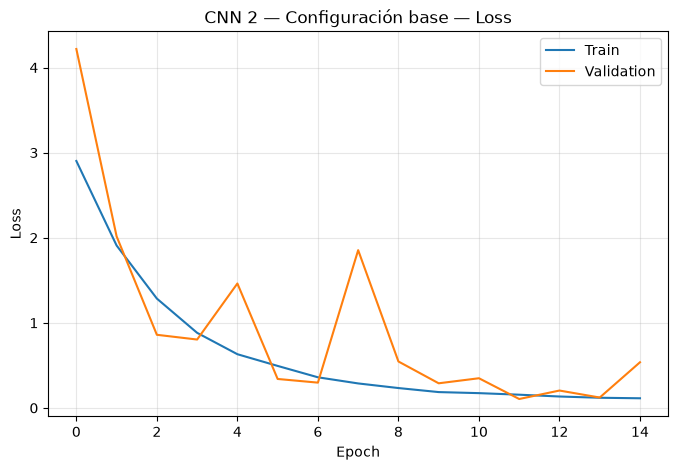

In [26]:
plot_training_history(
    history_cnn2_base,
    "CNN 2 — Configuración base"
)

In [27]:
cnn2_base_best_val_acc = max(
    history_cnn2_base.history["val_accuracy"]
)

cnn2_base_best_epoch = (
    np.argmax(history_cnn2_base.history["val_accuracy"]) + 1
)

print(
    f"Mejor validation accuracy: "
    f"{cnn2_base_best_val_acc:.4f}"
)

print(
    f"Mejor epoch: "
    f"{cnn2_base_best_epoch}"
)

Mejor validation accuracy: 0.9649
Mejor epoch: 12


### CNN 2 — Variación de hiperparámetros

Se evalúa una segunda configuración de CNN 2 aumentando la tasa de aprendizaje de **0.0005 a 0.001**. Todos los demás componentes de la arquitectura se mantienen constantes.

El objetivo es determinar si una tasa de aprendizaje mayor permite una convergencia más rápida sin perjudicar la estabilidad del entrenamiento de la arquitectura más profunda.

In [28]:
cnn2_variant = build_cnn2(
    learning_rate=0.001
)

early_stopping_cnn2_variant = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [29]:
history_cnn2_variant = cnn2_variant.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_cnn2_variant],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.1657 - loss: 2.9653 - val_accuracy: 0.0795 - val_loss: 4.2529
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 36s 81ms/step - accuracy: 0.3680 - loss: 2.0649 - val_accuracy: 0.4118 - val_loss: 2.0892
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 38s 85ms/step - accuracy: 0.5298 - loss: 1.4667 - val_accuracy: 0.7228 - val_loss: 0.8634
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 37s 82ms/step - accuracy: 0.6493 - loss: 1.0541 - val_accuracy: 0.7435 - val_loss: 0.8330
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 36s 81ms/step - accuracy: 0.7476 - loss: 0.7576 - val_accuracy: 0.7366 - val_loss: 0.8123
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 37s 82ms/step - accuracy: 0.8119 - loss: 0.5689 - val_accuracy: 0.8082 - val_loss: 0.6294
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 38s 85ms/step - accuracy: 0.8522 - loss: 0.4392 - val_accuracy: 0.7997 - val_loss: 0.6403
Epoch 8/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 37s 82ms/step - accuracy: 0.8827 - loss: 0.3528 - 

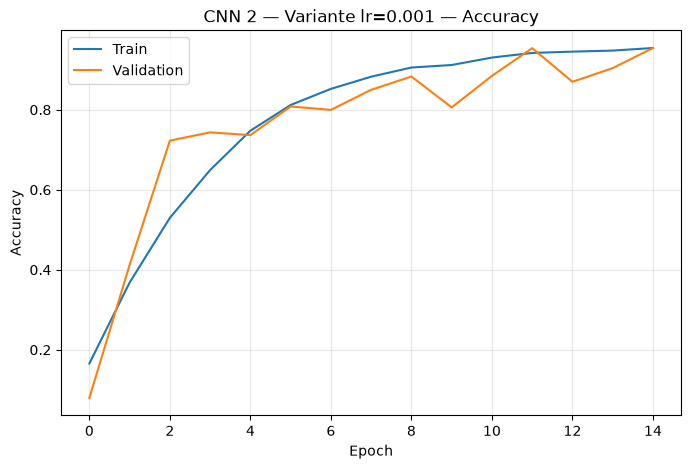

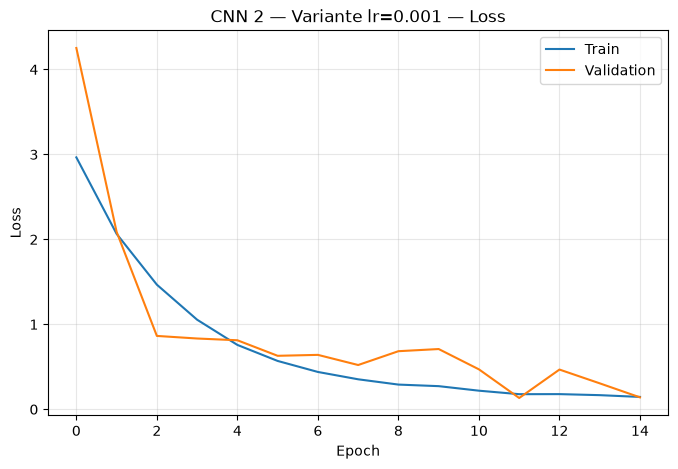

In [30]:
plot_training_history(
    history_cnn2_variant,
    "CNN 2 — Variante lr=0.001"
)

### Comparacion de CNN2

In [31]:
cnn2_variant_best_val_acc = max(
    history_cnn2_variant.history["val_accuracy"]
)

cnn2_variant_best_epoch = (
    np.argmax(history_cnn2_variant.history["val_accuracy"]) + 1
)

cnn2_results = pd.DataFrame({
    "Configuración": [
        "CNN2 Base",
        "CNN2 lr=0.001"
    ],
    "Learning rate": [
        0.0005,
        0.001
    ],
    "Mejor val_accuracy": [
        cnn2_base_best_val_acc,
        cnn2_variant_best_val_acc
    ],
    "Mejor epoch": [
        cnn2_base_best_epoch,
        cnn2_variant_best_epoch
    ]
})

cnn2_results

,Configuración,Learning rate,Mejor val_accuracy,Mejor epoch
0,CNN2 Base,0.0005,0.964860,12
1,CNN2 lr=0.001,0.0010,0.954351,15


In [32]:
if cnn2_base_best_val_acc >= cnn2_variant_best_val_acc:
    best_cnn2 = cnn2_base
    best_cnn2_name = "CNN2 Base (lr=0.0005)"
else:
    best_cnn2 = cnn2_variant
    best_cnn2_name = "CNN2 Variante (lr=0.001)"

print("Mejor configuración:", best_cnn2_name)

Mejor configuración: CNN2 Base (lr=0.0005)


### Resultado de CNN 2

La configuración base de CNN 2, con una tasa de aprendizaje de 0.0005, alcanzó el mejor accuracy de validación con **0.9649 (96.49%)**, mientras que la variante con learning rate de 0.001 obtuvo **0.9544 (95.44%)**.

Aunque ambas configuraciones alcanzaron un desempeño elevado, las curvas de validación presentan mayores fluctuaciones que las observadas en CNN 1, especialmente en la pérdida. Esto sugiere que la arquitectura más profunda presenta un entrenamiento menos estable. A pesar de ello, la configuración base alcanzó el mayor accuracy de validación observado hasta el momento.

Por lo tanto, se selecciona **CNN 2 con learning rate = 0.0005** como la mejor configuración de esta arquitectura. Su desempeño final será determinado posteriormente utilizando el conjunto de prueba.

## Red neuronal Fully Connected

Como modelo de referencia se implementa una red neuronal completamente conectada, sin capas convolucionales.

Cada imagen RGB de 64×64 píxeles es aplanada desde su representación tridimensional hasta un vector de 12,288 características. Este vector pasa por una capa densa de 512 neuronas con activación ReLU, seguida de Dropout de 0.3 y una segunda capa densa de 128 neuronas.

Finalmente, una capa de 29 neuronas con activación softmax genera las probabilidades correspondientes a las clases.

Este modelo permitirá comparar el desempeño de una red neuronal convencional frente a las CNN, las cuales aprovechan explícitamente la estructura espacial de las imágenes.

### Funcion de construccion

In [33]:
def build_fc(learning_rate=0.001, dropout_rate=0.3):
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Flatten(),

        layers.Dense(
            512,
            activation="relu"
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dense(
            29,
            activation="softmax"
        )
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [34]:
fc_base = build_fc(
    learning_rate=0.001,
    dropout_rate=0.3
)

fc_base.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,361,373 (24.27 MB)

 Trainable params: 6,361,373 (24.27 MB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento de Fully Connected

In [35]:
early_stopping_fc_base = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [36]:
history_fc_base = fc_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_fc_base],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 21s 45ms/step - accuracy: 0.0415 - loss: 3.5580 - val_accuracy: 0.0483 - val_loss: 3.2815
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.0582 - loss: 3.2488 - val_accuracy: 0.0847 - val_loss: 3.0955
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 44ms/step - accuracy: 0.0792 - loss: 3.0576 - val_accuracy: 0.1149 - val_loss: 2.8404
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 46ms/step - accuracy: 0.1004 - loss: 2.9303 - val_accuracy: 0.1649 - val_loss: 2.6853
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.1141 - loss: 2.8693 - val_accuracy: 0.1619 - val_loss: 2.7165
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.1241 - loss: 2.8155 - val_accuracy: 0.1445 - val_loss: 2.9865
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 43ms/step - accuracy: 0.1167 - loss: 2.9028 - val_accuracy: 0.1609 - val_loss: 2.7501


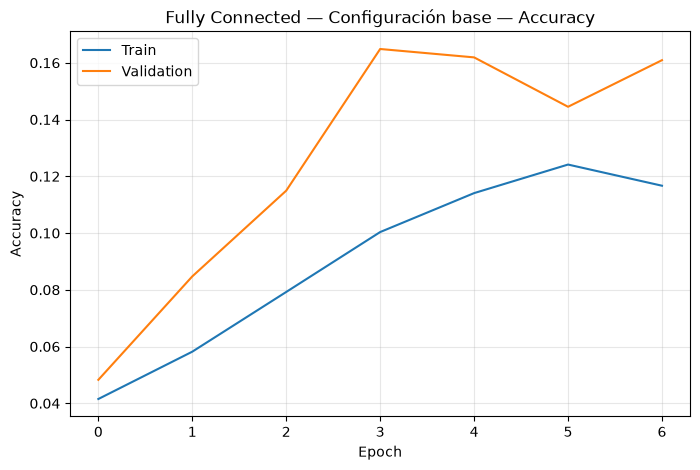

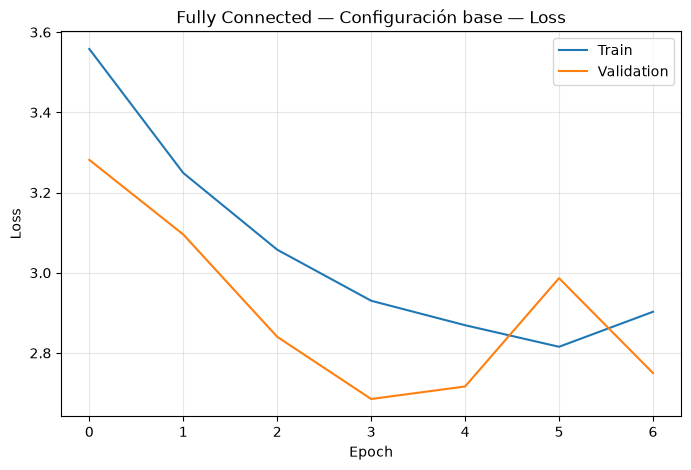

In [37]:
plot_training_history(
    history_fc_base,
    "Fully Connected — Configuración base"
)

In [38]:
fc_base_best_val_acc = max(
    history_fc_base.history["val_accuracy"]
)

fc_base_best_epoch = (
    np.argmax(history_fc_base.history["val_accuracy"]) + 1
)

print(
    f"Mejor validation accuracy: "
    f"{fc_base_best_val_acc:.4f}"
)

print(
    f"Mejor epoch: "
    f"{fc_base_best_epoch}"
)

Mejor validation accuracy: 0.1649
Mejor epoch: 4


### Fully Connected — Variación de hiperparámetros

Como variación experimental se incrementa el Dropout de **0.3 a 0.5**, manteniendo la arquitectura y el learning rate constantes.

Debido al elevado número de parámetros de la red fully-connected, se busca determinar si una regularización más fuerte permite reducir el sobreajuste y mejorar su capacidad de generalización sobre el conjunto de validación.

In [39]:
fc_variant = build_fc(
    learning_rate=0.001,
    dropout_rate=0.5
)

early_stopping_fc_variant = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [40]:
history_fc_variant = fc_variant.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping_fc_variant],
    verbose=1
)

Epoch 1/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 22s 48ms/step - accuracy: 0.0324 - loss: 3.5312 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 2/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 18s 39ms/step - accuracy: 0.0310 - loss: 3.3685 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 3/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.0310 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 4/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.0318 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 5/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.0331 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 6/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.0333 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673
Epoch 7/15
445/445 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.0332 - loss: 3.3677 - val_accuracy: 0.0345 - val_loss: 3.3673


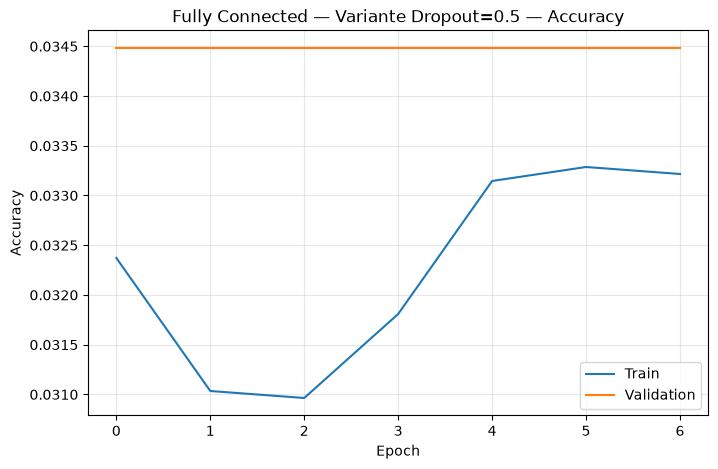

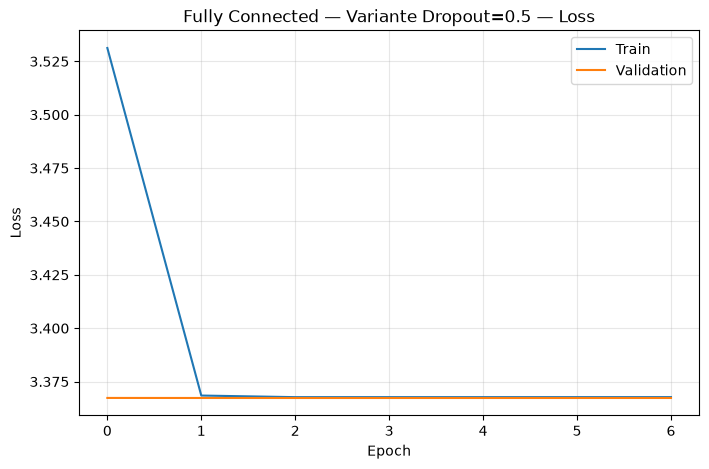

In [41]:
plot_training_history(
    history_fc_variant,
    "Fully Connected — Variante Dropout=0.5"
)

### Comparacion de configuraciones

In [42]:
fc_variant_best_val_acc = max(
    history_fc_variant.history["val_accuracy"]
)

fc_variant_best_epoch = (
    np.argmax(history_fc_variant.history["val_accuracy"]) + 1
)

fc_results = pd.DataFrame({
    "Configuración": [
        "FC Base",
        "FC Dropout=0.5"
    ],
    "Learning rate": [
        0.001,
        0.001
    ],
    "Dropout": [
        0.3,
        0.5
    ],
    "Mejor val_accuracy": [
        fc_base_best_val_acc,
        fc_variant_best_val_acc
    ],
    "Mejor epoch": [
        fc_base_best_epoch,
        fc_variant_best_epoch
    ]
})

fc_results

,Configuración,Learning rate,Dropout,Mejor val_accuracy,Mejor epoch
0,FC Base,0.001,0.3,0.164860,4
1,FC Dropout=0.5,0.001,0.5,0.034483,1


In [43]:
if fc_base_best_val_acc >= fc_variant_best_val_acc:
    best_fc = fc_base
    best_fc_name = "FC Base (Dropout=0.3)"
else:
    best_fc = fc_variant
    best_fc_name = "FC Variante (Dropout=0.5)"

print("Mejor configuración:", best_fc_name)

Mejor configuración: FC Base (Dropout=0.3)


### Resultado de la red Fully Connected

La configuración base de la red Fully Connected alcanzó un accuracy máximo de validación de **0.1649 (16.49%)**, mientras que incrementar el Dropout de 0.3 a 0.5 redujo el desempeño hasta **0.0345 (3.45%)**.

El incremento del Dropout produjo una regularización excesiva para esta configuración, impidiendo que el modelo aprendiera representaciones útiles. Por esta razón se selecciona la configuración base con Dropout de 0.3.

En comparación con las redes convolucionales, el desempeño de la red Fully Connected es considerablemente inferior. Una posible explicación es que el aplanamiento de la imagen elimina explícitamente su organización espacial, mientras que las capas convolucionales pueden aprender patrones locales relacionados con bordes, formas y configuraciones de la mano.

## Evaluacion final sobre test

In [44]:
def evaluate_model(model, X_test, y_test, model_name):
    # Probabilidades predichas
    y_prob = model.predict(
        X_test,
        batch_size=32,
        verbose=0
    )

    # Clase con mayor probabilidad
    y_pred = np.argmax(y_prob, axis=1)

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    print(model_name)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")

    return {
        "Modelo": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall
    }, y_pred

### Evaluacion de CNN1

In [45]:
cnn1_metrics, cnn1_pred = evaluate_model(
    best_cnn1,
    X_test,
    y_test,
    "CNN 1"
)

CNN 1
Accuracy:  0.9511
Precision: 0.9518
Recall:    0.9511


### Evaluacion de CNN2

In [46]:
cnn2_metrics, cnn2_pred = evaluate_model(
    best_cnn2,
    X_test,
    y_test,
    "CNN 2"
)

CNN 2
Accuracy:  0.9570
Precision: 0.9581
Recall:    0.9570


### Evaluacion de Fully Connected

In [47]:
fc_metrics, fc_pred = evaluate_model(
    best_fc,
    X_test,
    y_test,
    "Fully Connected"
)

Fully Connected
Accuracy:  0.1695
Precision: 0.1826
Recall:    0.1695


## Comparaciones

In [48]:
final_results = pd.DataFrame([
    cnn1_metrics,
    cnn2_metrics,
    fc_metrics
])

final_results

,Modelo,Accuracy,Precision,Recall
0,CNN 1,0.951067,0.951807,0.951067
1,CNN 2,0.956979,0.958108,0.956979
2,Fully Connected,0.169458,0.182647,0.169458


In [49]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    class_names,
    title
):
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    fig, ax = plt.subplots(
        figsize=(14, 14)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False
    )

    ax.set_title(title)

    plt.tight_layout()
    plt.show()

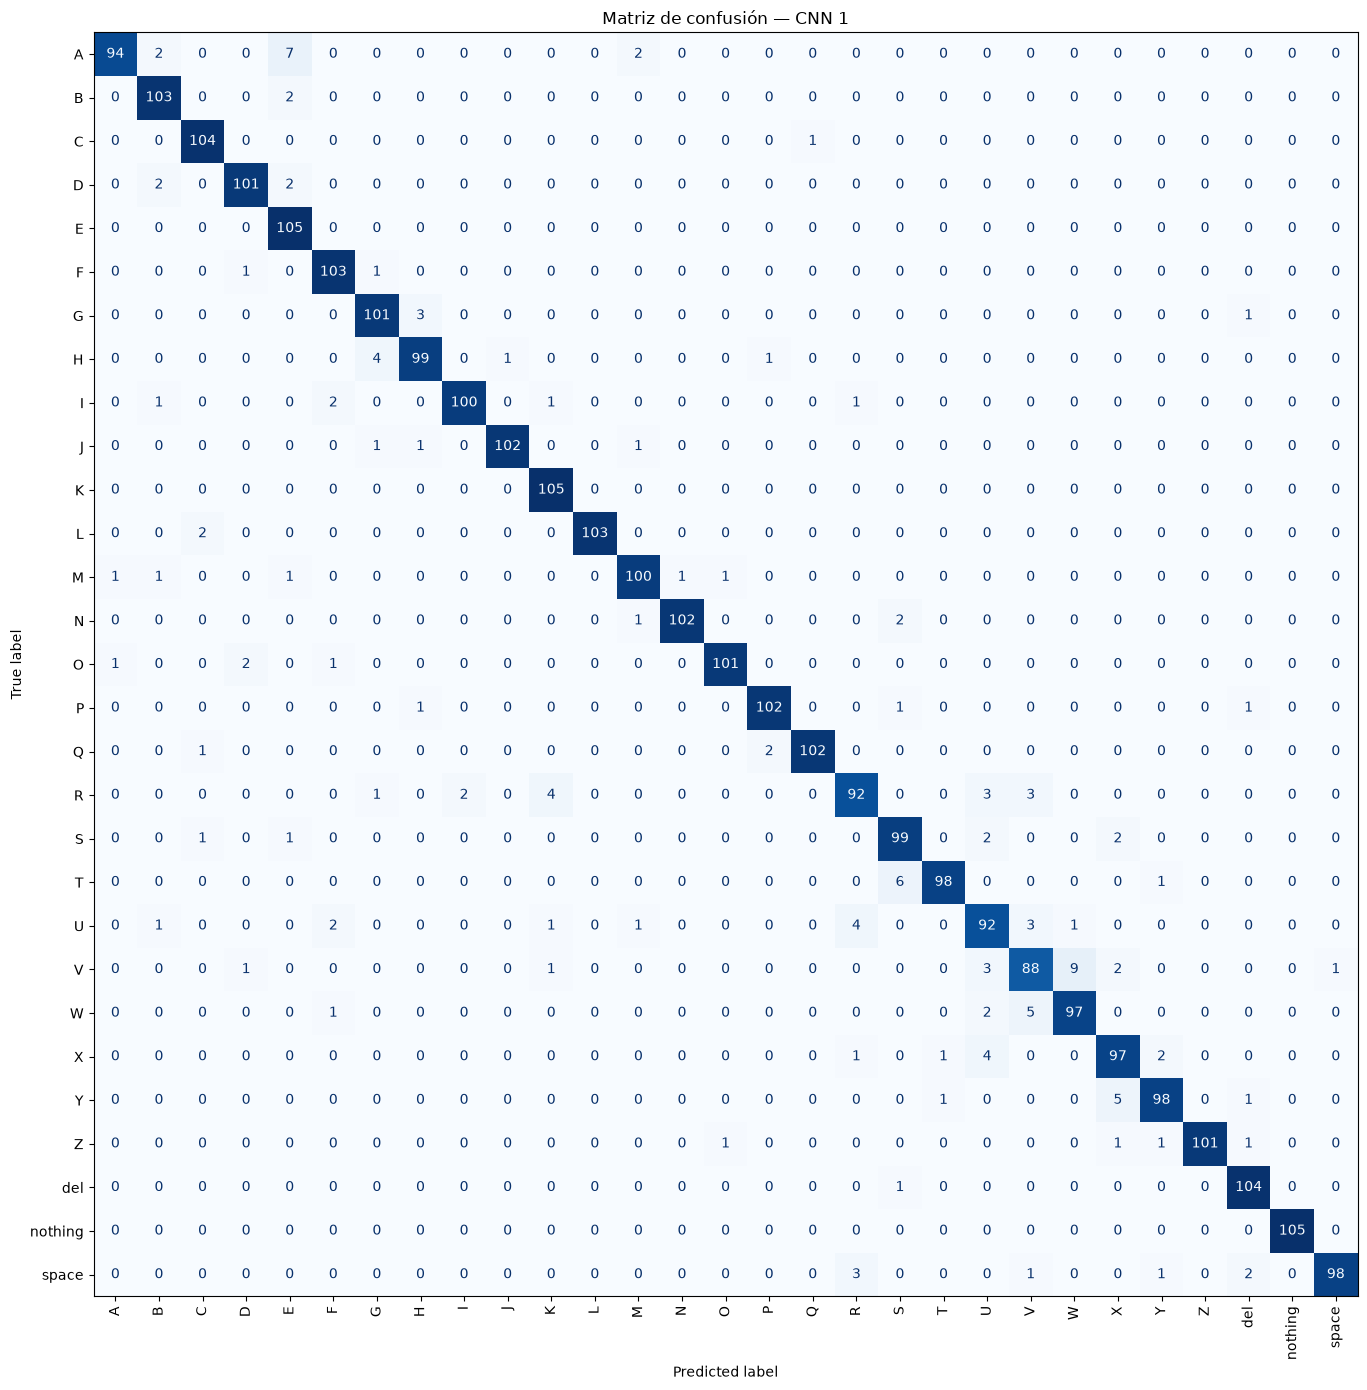

In [50]:
plot_confusion_matrix(
    y_test,
    cnn1_pred,
    classes,
    "Matriz de confusión — CNN 1"
)

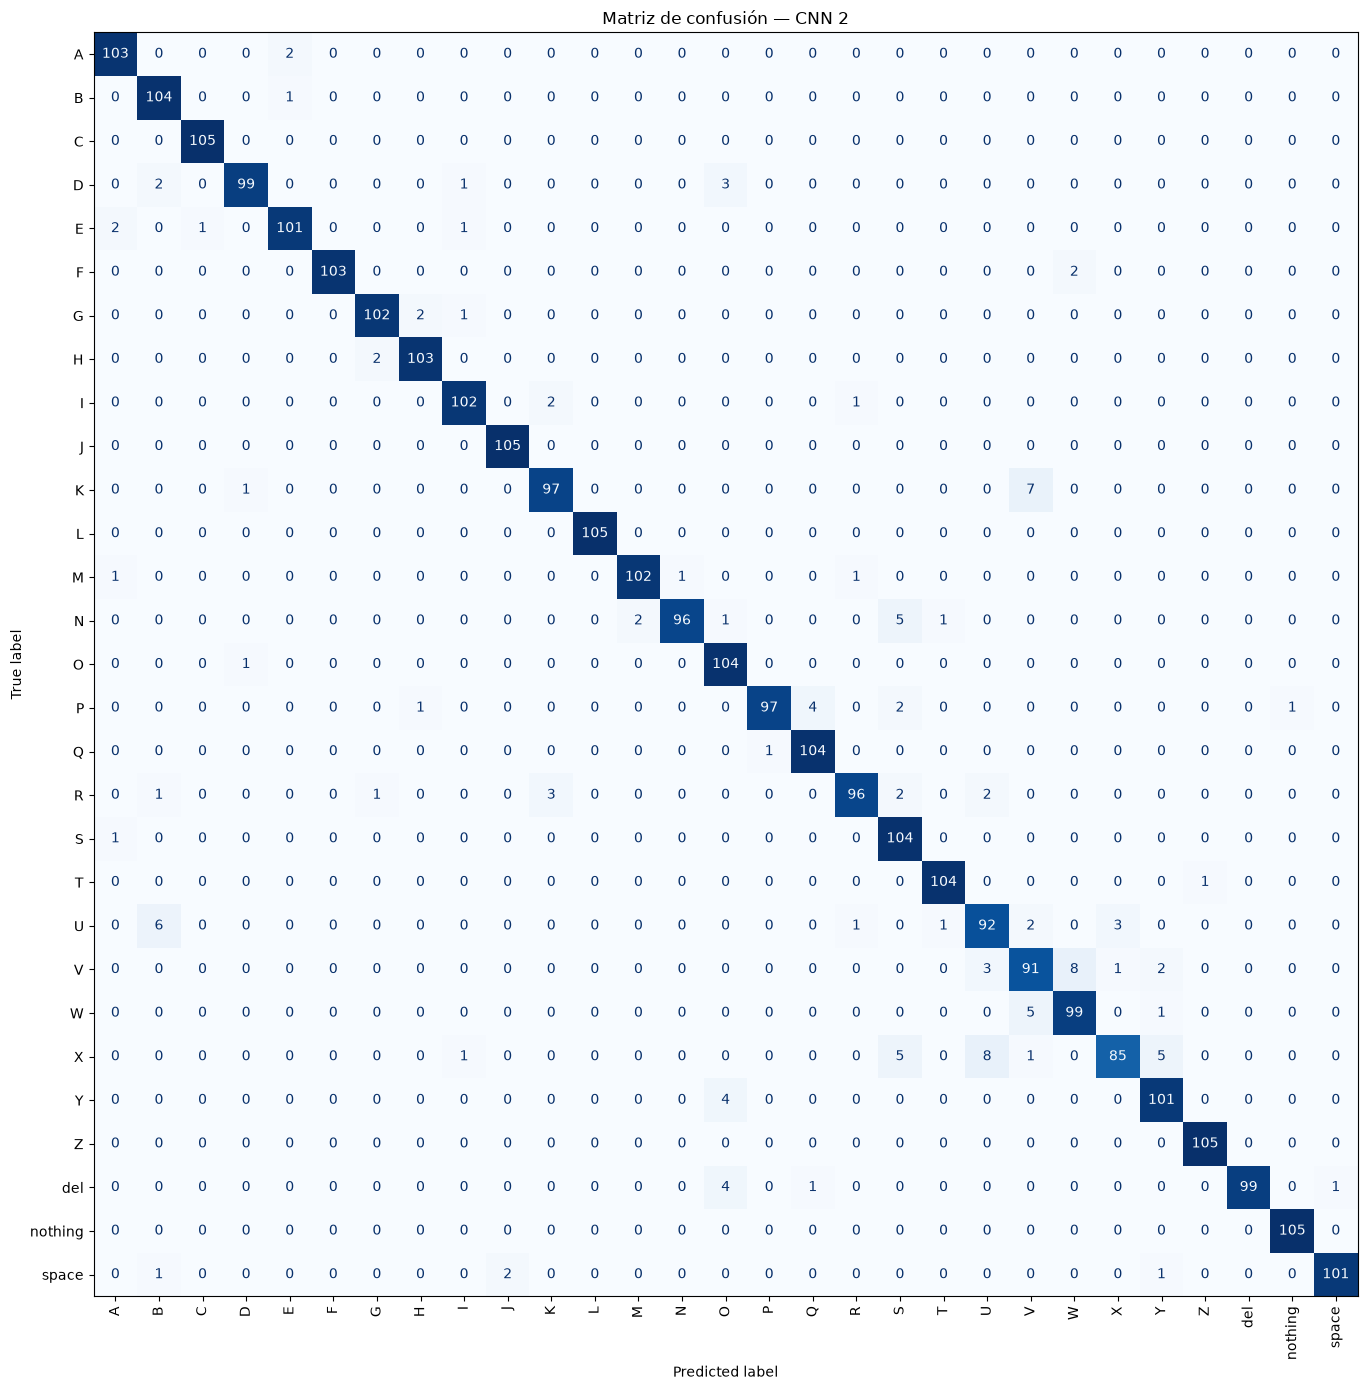

In [51]:
plot_confusion_matrix(
    y_test,
    cnn2_pred,
    classes,
    "Matriz de confusión — CNN 2"
)

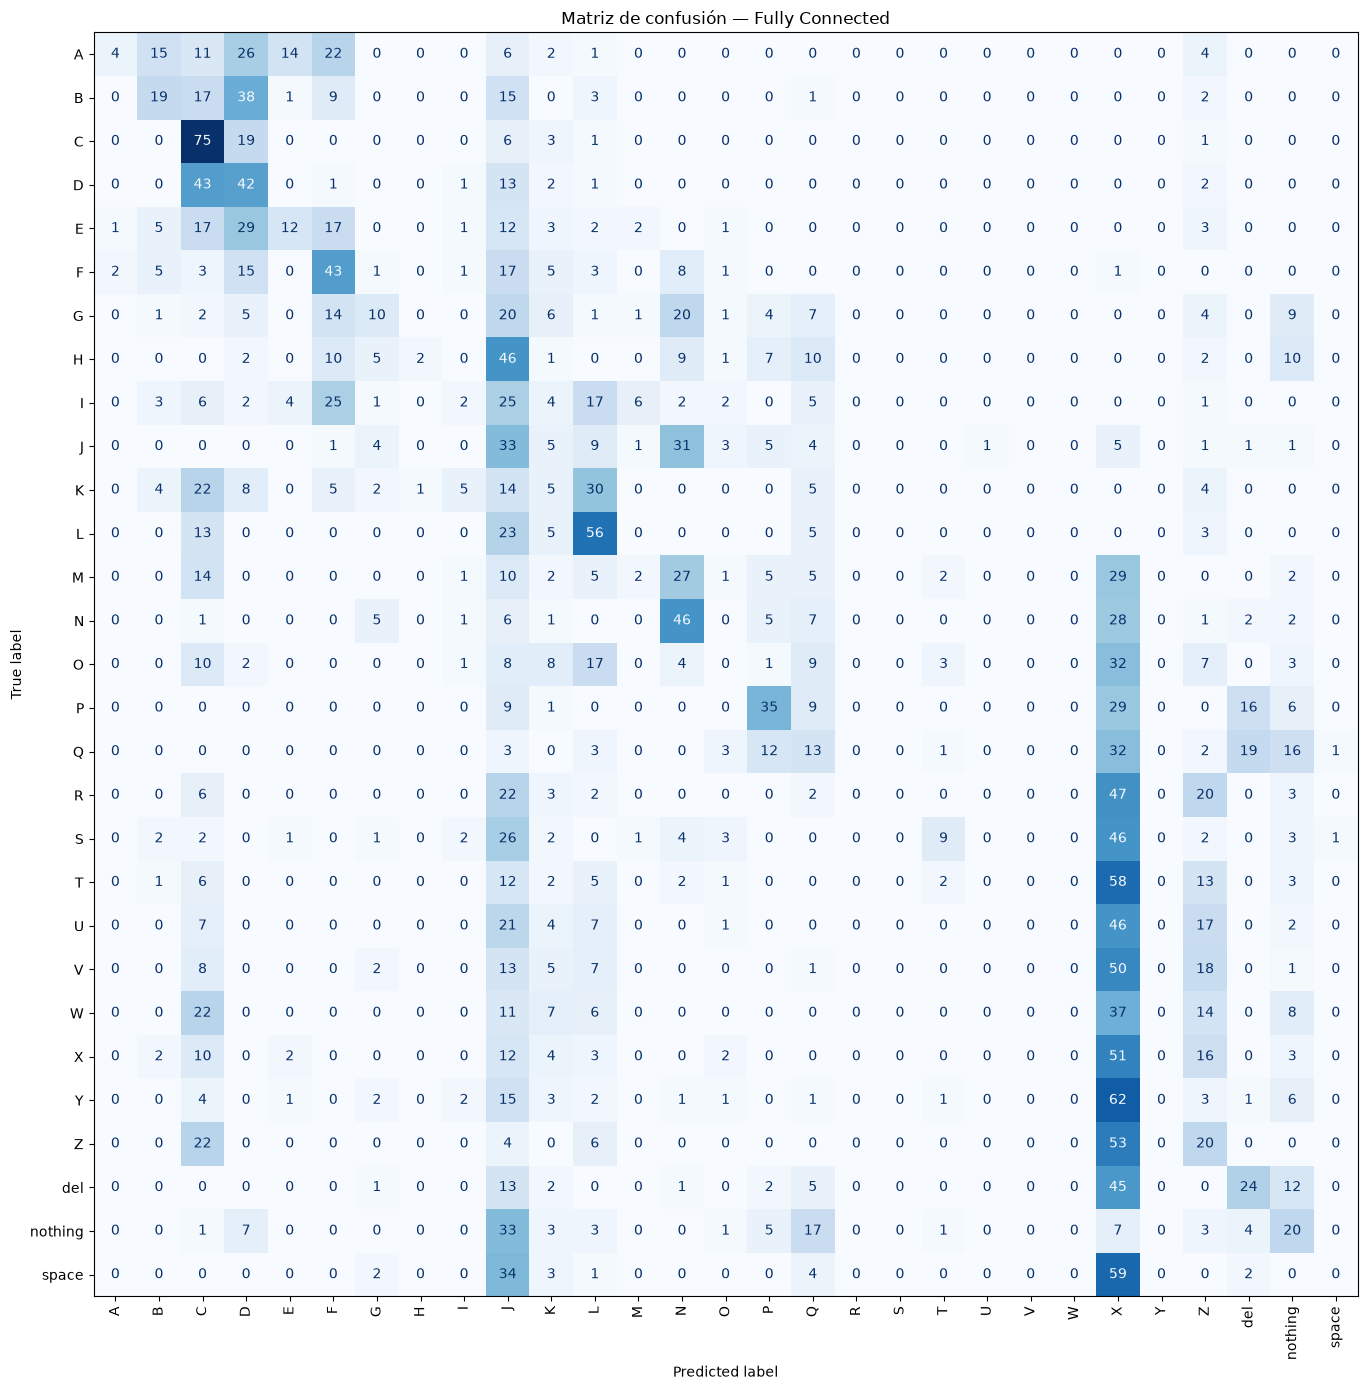

In [52]:
plot_confusion_matrix(
    y_test,
    fc_pred,
    classes,
    "Matriz de confusión — Fully Connected"
)

## Eleccion de CNN Ganadora

In [53]:
if cnn1_metrics["Accuracy"] >= cnn2_metrics["Accuracy"]:
    best_cnn = best_cnn1
    best_cnn_name = "CNN 1"
    best_cnn_metrics = cnn1_metrics
else:
    best_cnn = best_cnn2
    best_cnn_name = "CNN 2"
    best_cnn_metrics = cnn2_metrics

print("Mejor CNN:", best_cnn_name)
print(
    f"Test accuracy: "
    f"{best_cnn_metrics['Accuracy']:.4f}"
)

Mejor CNN: CNN 2
Test accuracy: 0.9570


## Guardar y validar archivo

In [54]:
best_cnn_path = MODELS_DIR / "best_cnn.keras"

best_cnn.save(best_cnn_path)

print(
    f"Modelo guardado en: {best_cnn_path}"
)

Modelo guardado en: ../models/best_cnn.keras


In [55]:
assert best_cnn_path.exists()

print("✓ best_cnn.keras generado correctamente.")

✓ best_cnn.keras generado correctamente.


In [56]:
# Esta celda solo esta para validar que se puede cargar correctamente.
# No queremos tener la sorpresa despues de algun error con el archivo.

loaded_model = keras.models.load_model(
    best_cnn_path
)

print("✓ Modelo cargado correctamente.")

✓ Modelo cargado correctamente.


### Verificacion de prediccion del modelo guardado

In [57]:
sample_predictions = loaded_model.predict(
    X_test[:10],
    verbose=0
)

sample_classes = np.argmax(
    sample_predictions,
    axis=1
)

print("Predicciones:", sample_classes)
print("Valores reales:", y_test[:10])

Predicciones: [ 2  8 11 17 28  2 17  6 27 13]
Valores reales: [ 2  8 11 17 28  2 17  6 27 13]


## Comparación final de los modelos

Los tres modelos seleccionados fueron evaluados utilizando el mismo conjunto de prueba, compuesto por 3,045 imágenes que no fueron utilizadas durante el entrenamiento ni durante la selección de hiperparámetros.

**CNN 1** obtuvo un accuracy de **95.11%**, una precision macro de **95.18%** y un recall macro de **95.11%**. Por su parte, **CNN 2** alcanzó los mejores resultados, con un accuracy de **95.70%**, precision macro de **95.81%** y recall macro de **95.70%**.

La red **Fully Connected** presentó un desempeño considerablemente inferior, alcanzando únicamente **16.95% de accuracy**, **18.26% de precision macro** y **16.95% de recall macro**. A pesar de poseer una cantidad considerablemente mayor de parámetros que las CNN, su desempeño fue inferior. Esto evidencia la importancia de las capas convolucionales para este problema, ya que permiten aprovechar la estructura espacial de las imágenes y aprender características locales relevantes para distinguir las diferentes configuraciones de la mano.

Entre las arquitecturas convolucionales, **CNN 2 obtuvo el mayor accuracy sobre el conjunto de prueba (95.70%)**, superando ligeramente el 95.11% obtenido por CNN 1. Por esta razón, CNN 2 fue seleccionada como el mejor modelo convolucional y almacenada como `models/best_cnn.keras` para las siguientes etapas del laboratorio.

Las arquitecturas y su justificación teórica se encuentran documentadas en `docs/report/03_seleccion_modelos.md`.